# Examination Timetabling — Evaluation and Constraint-Aware Scheduling

This notebook consolidates the evaluation results and builds one constraint-aware candidate timetable from the Nottingham benchmark conflict graph.

## Important scope note
The model enforces the listed period, graph-conflict, precedence, succession, different-time, spread-out, and **31 non-conflicting coincidence groups**. Two coincidence groups are deliberately left unresolved because their members have edges in the student-conflict graph:
- `C81MJAE1` and `C81MSAE1`
- `M12353E1` and `M13369E1`

The benchmark also includes room assignments/capacities, special room usage, earliness priorities, additional spread-out semantics, and other rules. Those are **not all represented in this model yet**, so a successful solver status does not mean the entire original benchmark is fully feasible. The final validation report will say this explicitly.

## 1. Imports and project paths

In [1]:
from pathlib import Path
import pickle
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from datetime import date, timedelta

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
GRAPH_PATH = PROJECT_ROOT / "data" / "processed" / "conflict_graph.gpickle"
OUTPUT_PATH = PROJECT_ROOT / "data" / "processed" / "constraint_aware_candidate_schedule.csv"

with open(GRAPH_PATH, "rb") as f:
    G = pickle.load(f)

print(f"Project root: {PROJECT_ROOT}")
print(f"Exams: {G.number_of_nodes():,}")
print(f"Conflict edges: {G.number_of_edges():,}")

Project root: c:\Users\Nethmi\Documents\GitHub\adaptive-exam-timetabling
Exams: 800
Conflict edges: 9,990


## 2. Reproduce the recorded algorithm comparison

In [2]:
results_df = pd.DataFrame([
    {"Algorithm": "Greedy (Alphabetical)", "Periods": 25, "Conflict Violations": 0},
    {"Algorithm": "Welsh–Powell", "Periods": 18, "Conflict Violations": 0},
    {"Algorithm": "DSATUR", "Periods": 17, "Conflict Violations": 0},
    {"Algorithm": "Adaptive v1", "Periods": 17, "Conflict Violations": 0},
    {"Algorithm": "Adaptive v2", "Periods": 18, "Conflict Violations": 0},
    {"Algorithm": "Adaptive v3", "Periods": 17, "Conflict Violations": 0},
])

spacing_penalties = {
    "Greedy (Alphabetical)": None,
    "Welsh–Powell": None,
    "DSATUR": 8630,
    "Adaptive v1": 8576,
    "Adaptive v2": 8716,
    "Adaptive v3": 974,
}
results_df["Same-Day Adjacent-Exam Penalty"] = results_df["Algorithm"].map(spacing_penalties)
baseline_penalty = spacing_penalties["DSATUR"]
results_df["Penalty Reduction (%)"] = results_df["Same-Day Adjacent-Exam Penalty"].apply(
    lambda v: round((baseline_penalty - v) / baseline_penalty * 100, 2)
    if pd.notna(v) else None
)
display(results_df)

,Algorithm,Periods,Conflict Violations,Same-Day Adjacent-Exam Penalty,Penalty Reduction (%)
0,Greedy (Alphabetical),25,0,NaN,NaN
1,Welsh–Powell,18,0,NaN,NaN
2,DSATUR,17,0,8630.0,0.00
3,Adaptive v1,17,0,8576.0,0.63
4,Adaptive v2,18,0,8716.0,-1.00
5,Adaptive v3,17,0,974.0,88.71


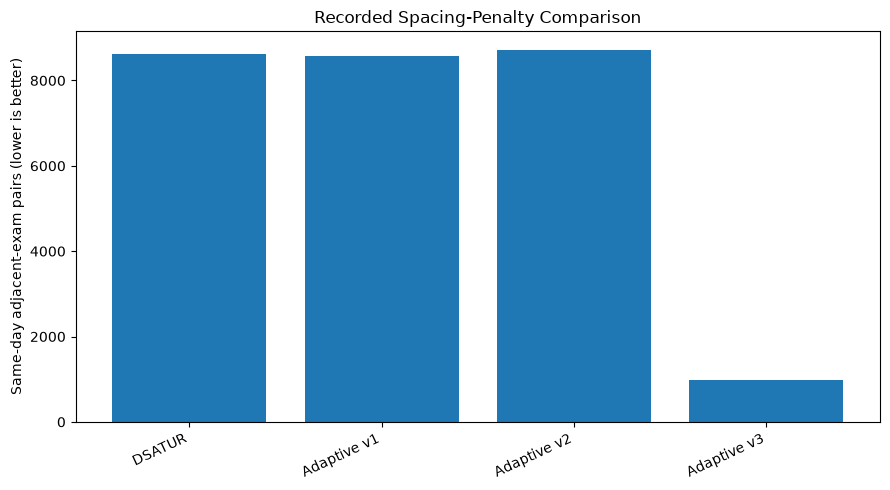

In [3]:
plot_df = results_df.dropna(subset=["Same-Day Adjacent-Exam Penalty"])
plt.figure(figsize=(9, 5))
plt.bar(plot_df["Algorithm"], plot_df["Same-Day Adjacent-Exam Penalty"])
plt.ylabel("Same-day adjacent-exam pairs (lower is better)")
plt.title("Recorded Spacing-Penalty Comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 3. Build the official calendar periods

The benchmark calendar has 32 periods: weekdays have 09:00, 13:30, and 16:30; Saturdays have only 09:00; Sundays are excluded.

In [4]:
period_rows = []
current_date = date(1995, 1, 23)
last_date = date(1995, 2, 4)
period_index = 0

while current_date <= last_date:
    if current_date.weekday() < 5:
        times = ["09:00", "13:30", "16:30"]
    elif current_date.weekday() == 5:
        times = ["09:00"]
    else:
        times = []

    for exam_time in times:
        period_rows.append({
            "period_index": period_index,
            "date": pd.Timestamp(current_date),
            "day": current_date.strftime("%A"),
            "time": exam_time,
        })
        period_index += 1
    current_date += timedelta(days=1)

periods_df = pd.DataFrame(period_rows)
display(periods_df)
print("Calendar periods:", len(periods_df))

,period_index,date,day,time
0,0,1995-01-23,Monday,09:00
1,1,1995-01-23,Monday,13:30
2,2,1995-01-23,Monday,16:30
3,3,1995-01-24,Tuesday,09:00
4,4,1995-01-24,Tuesday,13:30
5,5,1995-01-24,Tuesday,16:30
6,6,1995-01-25,Wednesday,09:00
7,7,1995-01-25,Wednesday,13:30
8,8,1995-01-25,Wednesday,16:30
9,9,1995-01-26,Thursday,09:00


Calendar periods: 32


## 4. Encode the benchmark constraints represented in this model

In [5]:
all_periods = periods_df["period_index"].tolist()

fixed_rules = {
    "F321Q6E1": [12],  # 27 January
    "F321T6E1": [16],  # 30 January
    "H21M01E1": [0, 1, 2, 3, 4, 5],  # 23–24 January
    "H22M02E1": [0, 1, 2, 3, 4, 5],
    "H2CM04E1": [0, 1, 2, 3, 4, 5],
    "G13RE2E1": periods_df.loc[
        periods_df["date"] < pd.Timestamp("1995-01-30"), "period_index"
    ].tolist(),
}

morning_periods = periods_df.loc[
    periods_df["time"] == "09:00", "period_index"
].tolist()
thursday_afternoon_periods = periods_df.loc[
    (periods_df["day"] == "Thursday") &
    (periods_df["time"].isin(["13:30", "16:30"])),
    "period_index"
].tolist()

fixed_rules["K1AHWAE2"] = morning_periods
fixed_rules["H63122E1"] = morning_periods
fixed_rules["V13101E1"] = thursday_afternoon_periods

precedence_rules = [
    ("F13P03E1", "F13X03E1"),
    ("F13P05E1", "F13X04E1"),
]
succession_rules = [("H3BFM2E1", "H3BFM2E2")]
different_time_rules = [("H8B040E1", "H8C001E1")]

spread_out_groups = [
    ["Q33211E1", "Q33307E1", "Q33308E1"],
    ["B12301E1", "B12302E1", "B12303E1", "B12320E1"],
    ["B13103E1", "C13571E1", "C13572E1"],
]

coincidence_groups = [
    ["LK44FAE1", "LK44GAE1", "LK44SAE1"],
    ["LKC3FAE1", "LKC3GAE1", "LKC3SAE1", "LKC3RAE1"],
    ["C81IAAE1", "C81J1AE2", "C81J4AE2", "C81HAAE1"],
    ["C81HBAE1", "C81IBAE1", "C81J1AE1", "C81J2AE1", "C81J3AE1"],
    ["C81HCAE1", "C81ICAE1", "C81J2AE2", "C81J4AE1", "C81J5AE1"],
    ["C81HDAE1", "C81IDAE1", "C81J3AE2", "C81J5AE2"],
    ["C81MJAE1", "C81MSAE1", "C82MCPE1"],
    ["C82BCSE1", "C82BUAE1"],
    ["C82MHAE1", "C82MJAE1"],
    ["R23102E1", "R23104E1"],
    ["F12I01E1", "F12X04E1", "F12X05E1"],
    ["F12O01E1", "F12X04E2"],
    ["F12P01E1", "F12P02E1", "F12P03E1", "F12X04E3"],
    ["F13I01E1", "F13I02E1", "F13X01E1"],
    ["F13O01E1", "F13O03E1"],
    ["F13X03E1", "F13X04E1"],
    ["M11341E1", "M11345E1"],
    ["M11343E1", "M11347E1"],
    ["M12353E1", "M13369E1"],
    ["H8A009E1", "H8A011E1"],
    ["Q31301E1", "Q3A301E1"],
    ["Q32302E1", "Q3A303E1"],
    ["H22C20E1", "H23C20E1", "H24C20E1", "H23CEOE1"],
    ["HG2J3BE1", "HGCEMME1"],
    ["HG3J5AE1", "HG3J5BE1"],
    ["HGCEMAE1", "HGCEMBE1", "HGCEMCE1"],
    ["G5P002E1", "C8CXESE1"],
    ["L31073E1", "L31107E1"],
    ["V7A101E1", "V7A117E1"],
    ["L11101E1", "L11102E1"],
    ["L11110E1", "L11111E1"],
    ["L11130E1", "L11140E1"],
    ["M11351E1", "M11451E1"],
]

# These two groups have an internal conflict edge and are not forced into one period.
unresolved_coincidence_groups = [
    ["C81MJAE1", "C81MSAE1", "C82MCPE1"],
    ["M12353E1", "M13369E1"],
]
unresolved_members = set().union(*map(set, unresolved_coincidence_groups))
compatible_coincidence_groups = [
    group for group in coincidence_groups
    if not set(group) & unresolved_members
]

print("Fixed-rule exams:", len(fixed_rules))
print("Coincidence groups enforced:", len(compatible_coincidence_groups))
print("Coincidence groups requiring source interpretation:", len(unresolved_coincidence_groups))

Fixed-rule exams: 9
Coincidence groups enforced: 31
Coincidence groups requiring source interpretation: 2


## 5. Check constraint IDs and coincidence-group consistency

A coincidence group cannot be scheduled together if any two members share an edge in the student-conflict graph. The two conflicting groups are explicitly excluded from equality constraints; all other groups are checked before model construction.

In [6]:
constraint_exam_ids = set(fixed_rules)
for group in coincidence_groups + spread_out_groups:
    constraint_exam_ids.update(group)
for pair in precedence_rules + succession_rules + different_time_rules:
    constraint_exam_ids.update(pair)

missing_constraint_exams = sorted(constraint_exam_ids - set(G.nodes()))
print("Constraint exam IDs missing from graph:", missing_constraint_exams)

internal_conflicts = []
for idx, group in enumerate(compatible_coincidence_groups, start=1):
    for i, a in enumerate(group):
        for b in group[i + 1:]:
            if G.has_edge(a, b):
                internal_conflicts.append((idx, a, b))

print("Internal conflicts in groups selected for enforcement:", internal_conflicts)
if missing_constraint_exams:
    raise ValueError("Some benchmark constraint exam IDs are absent from the graph.")
if internal_conflicts:
    raise ValueError("A coincidence group selected for enforcement contains a conflict edge.")

Constraint exam IDs missing from graph: []
Internal conflicts in groups selected for enforcement: []


## 6. Solve the constraint model with OR-Tools CP-SAT

If OR-Tools is not installed in the notebook environment, install it in the active project environment first with `python -m pip install ortools`, then restart the kernel and run the notebook from the top.

The objective minimizes the number of calendar periods used. It is not yet a room-feasibility model and does not optimize the spacing penalty.

In [7]:
import sys
print("Notebook Python:", sys.executable)
%pip install ortools

Notebook Python: c:\Users\Nethmi\Documents\GitHub\adaptive-exam-timetabling\.venv\Scripts\python.exe
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
from ortools.sat.python import cp_model
print("OR-Tools installed successfully")

OR-Tools installed successfully


In [9]:
try:
    from ortools.sat.python import cp_model
except ImportError as exc:
    raise ImportError(
        "OR-Tools is required for this solver. In the project terminal run: "
        "python -m pip install ortools, then restart the notebook kernel."
    ) from exc

model = cp_model.CpModel()
exams = sorted(G.nodes())
periods = list(periods_df["period_index"])
x = {
    (exam, p): model.NewBoolVar(f"x_{exam}_{p}")
    for exam in exams for p in periods
}
period_of = {
    exam: model.NewIntVar(min(periods), max(periods), f"period_{exam}")
    for exam in exams
}
used = {p: model.NewBoolVar(f"used_{p}") for p in periods}

# Every exam has exactly one period and the integer period variable matches it.
for exam in exams:
    model.Add(sum(x[exam, p] for p in periods) == 1)
    model.Add(period_of[exam] == sum(p * x[exam, p] for p in periods))
    for p in periods:
        model.Add(x[exam, p] <= used[p])

# Student conflict edges cannot share a period.
for a, b in G.edges():
    for p in periods:
        model.Add(x[a, p] + x[b, p] <= 1)

# Fixed dates/times and restricted time-of-day rules.
for exam, allowed in fixed_rules.items():
    allowed_set = set(allowed)
    model.Add(sum(x[exam, p] for p in allowed_set) == 1)
    for p in set(periods) - allowed_set:
        model.Add(x[exam, p] == 0)

# Coincidence groups are assigned to one common period.
for group in compatible_coincidence_groups:
    anchor = group[0]
    for exam in group[1:]:
        model.Add(period_of[exam] == period_of[anchor])

# Precedence: the earlier exam must be in a strictly earlier period.
for earlier, later in precedence_rules:
    model.Add(period_of[earlier] < period_of[later])

# Immediate succession means consecutive calendar-period indices.
for first, second in succession_rules:
    model.Add(period_of[second] == period_of[first] + 1)

# Different-time restriction.
for a, b in different_time_rules:
    model.Add(period_of[a] != period_of[b])

# Preliminary spread-out interpretation: all members occupy distinct periods.
# The benchmark's special wording for some groups needs further source review.
for group in spread_out_groups:
    for i, a in enumerate(group):
        for b in group[i + 1:]:
            model.Add(period_of[a] != period_of[b])

# Minimize the number of used periods.
for p in periods:
    model.Add(sum(x[exam, p] for exam in exams) <= len(exams) * used[p])
model.Minimize(sum(used[p] for p in periods))

solver = cp_model.CpSolver()
solver.parameters.max_time_in_seconds = 300
solver.parameters.num_search_workers = 8
status = solver.Solve(model)

print("Solver status:", solver.StatusName(status))
if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    schedule_rows = []
    period_lookup = periods_df.set_index("period_index")
    for exam in exams:
        p = solver.Value(period_of[exam])
        period = period_lookup.loc[p]
        schedule_rows.append({
            "exam_id": exam,
            "period_index": p,
            "date": period["date"],
            "day": period["day"],
            "time": period["time"],
        })
    final_schedule = pd.DataFrame(schedule_rows).sort_values(
        ["period_index", "exam_id"]
    ).reset_index(drop=True)
    print("Periods used:", final_schedule["period_index"].nunique())
else:
    final_schedule = None
    print("No candidate schedule was returned. Review model constraints or allow more solve time.")

Solver status: FEASIBLE
Periods used: 16


## 7. Validate the generated schedule

In [10]:
if final_schedule is None:
    raise RuntimeError("No schedule exists to validate because the solver returned no solution.")

schedule_by_exam = final_schedule.set_index("exam_id")
period_by_exam = schedule_by_exam["period_index"].to_dict()

validation_rows = []

def check(name, passed, details=""):
    validation_rows.append({"Check": name, "Pass": bool(passed), "Details": details})

check(
    "All graph exams scheduled exactly once",
    len(final_schedule) == G.number_of_nodes()
    and final_schedule["exam_id"].nunique() == G.number_of_nodes()
    and set(final_schedule["exam_id"]) == set(G.nodes()),
    f"Rows={len(final_schedule)}; unique IDs={final_schedule['exam_id'].nunique()}",
)

conflicts = [
    (a, b) for a, b in G.edges()
    if period_by_exam[a] == period_by_exam[b]
]
check("No student-conflict edge shares a period", not conflicts, f"Violations={len(conflicts)}")

for exam, allowed in fixed_rules.items():
    check(
        f"Allowed period: {exam}",
        period_by_exam[exam] in set(allowed),
        f"Assigned={period_by_exam[exam]}",
    )

for earlier, later in precedence_rules:
    check(
        f"Precedence: {earlier} before {later}",
        period_by_exam[earlier] < period_by_exam[later],
        f"Periods={period_by_exam[earlier]}, {period_by_exam[later]}",
    )

for first, second in succession_rules:
    check(
        f"Immediate succession: {first} then {second}",
        period_by_exam[second] == period_by_exam[first] + 1,
        f"Periods={period_by_exam[first]}, {period_by_exam[second]}",
    )

for a, b in different_time_rules:
    check(
        f"Different periods: {a} and {b}",
        period_by_exam[a] != period_by_exam[b],
        f"Periods={period_by_exam[a]}, {period_by_exam[b]}",
    )

for idx, group in enumerate(spread_out_groups, start=1):
    assigned = [period_by_exam[e] for e in group]
    check(
        f"Spread-out group {idx} (preliminary distinct-period interpretation)",
        len(set(assigned)) == len(assigned),
        f"Periods={assigned}",
    )

for idx, group in enumerate(compatible_coincidence_groups, start=1):
    assigned = [period_by_exam[e] for e in group]
    check(
        f"Coincidence group enforced {idx}",
        len(set(assigned)) == 1,
        f"Periods={assigned}",
    )

validation_df = pd.DataFrame(validation_rows)
display(validation_df)
print(f"Checks passed: {validation_df['Pass'].sum()} / {len(validation_df)}")
print(f"Checks failed: {(~validation_df['Pass']).sum()} / {len(validation_df)}")
print("Unresolved coincidence groups:", unresolved_coincidence_groups)

,Check,Pass,Details
0,All graph exams scheduled exactly once,True,Rows=800; unique IDs=800
1,No student-conflict edge shares a period,True,Violations=0
2,Allowed period: F321Q6E1,True,Assigned=12
3,Allowed period: F321T6E1,True,Assigned=16
4,Allowed period: H21M01E1,True,Assigned=1
5,Allowed period: H22M02E1,True,Assigned=4
6,Allowed period: H2CM04E1,True,Assigned=0
7,Allowed period: G13RE2E1,True,Assigned=10
8,Allowed period: K1AHWAE2,True,Assigned=28
9,Allowed period: H63122E1,True,Assigned=16


Checks passed: 49 / 49
Checks failed: 0 / 49
Unresolved coincidence groups: [['C81MJAE1', 'C81MSAE1', 'C82MCPE1'], ['M12353E1', 'M13369E1']]


## 8. Save the candidate timetable and report scope limitations

The CSV is a candidate timetable for the constraints explicitly modelled above. It must not be described as fully benchmark-feasible until room allocations/capacities, special room constraints, earliness priorities, the unresolved coincidence groups, and the benchmark's exact spread-out/coincidence semantics are implemented and validated.

In [11]:
if final_schedule is not None:
    OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    final_schedule.to_csv(OUTPUT_PATH, index=False)
    print("Saved candidate schedule to:", OUTPUT_PATH)
    print("Scheduled exams:", len(final_schedule))
    print("Unique periods:", final_schedule["period_index"].nunique())
    print("Conflict violations:", len(conflicts))

Saved candidate schedule to: c:\Users\Nethmi\Documents\GitHub\adaptive-exam-timetabling\data\processed\constraint_aware_candidate_schedule.csv
Scheduled exams: 800
Unique periods: 16
Conflict violations: 0


## 9. Research interpretation and limitations

The earlier Adaptive v3 experiment reduced the proposed same-day adjacent-exam penalty from 8,630 (DSATUR) to 974 (88.71%) while using 17 periods and having zero graph-conflict violations. That is a result from a colour-order optimization experiment, not proof of a fully feasible official timetable.

The CP-SAT candidate generated here solves the period constraints encoded in this notebook and minimizes periods used. The spacing penalty is not currently part of its objective, and room feasibility is not modeled. Report those as limitations in the research write-up rather than claiming all benchmark constraints are solved.

In [12]:
from pathlib import Path

output_path = Path("../data/processed/cp_sat_schedule.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

final_schedule.to_csv(output_path, index=False)

print(f"Schedule saved to: {output_path.resolve()}")
print(f"Exams scheduled: {len(final_schedule)}")
print(f"Periods used: {final_schedule['period_index'].nunique()}")

Schedule saved to: C:\Users\Nethmi\Documents\GitHub\adaptive-exam-timetabling\data\processed\cp_sat_schedule.csv
Exams scheduled: 800
Periods used: 16


In [13]:
import pandas as pd
from pathlib import Path

schedule_path = Path("../data/processed/cp_sat_schedule.csv")
saved_schedule = pd.read_csv(schedule_path)

print("Rows:", len(saved_schedule))
print("Unique exams:", saved_schedule["exam_id"].nunique())
print("Periods used:", saved_schedule["period_index"].nunique())
print("Missing values:\n", saved_schedule.isnull().sum())
print("\nFirst five rows:")
display(saved_schedule.head())

assert len(saved_schedule) == 800
assert saved_schedule["exam_id"].nunique() == 800
assert saved_schedule["period_index"].nunique() == 16

print("\nExport validation passed.")

Rows: 800
Unique exams: 800
Periods used: 16
Missing values:
 exam_id         0
period_index    0
date            0
day             0
time            0
dtype: int64

First five rows:


,exam_id,period_index,date,day,time
0,AAA024E1,0,1995-01-23,Monday,09:00
1,B31105E1,0,1995-01-23,Monday,09:00
2,B32327E1,0,1995-01-23,Monday,09:00
3,B33563E1,0,1995-01-23,Monday,09:00
4,C12321E1,0,1995-01-23,Monday,09:00



Export validation passed.


In [14]:
import pandas as pd

saved_schedule = pd.read_csv("../data/processed/cp_sat_schedule.csv")

# Map each exam to its assigned period
exam_period = dict(
    zip(saved_schedule["exam_id"], saved_schedule["period_index"])
)

# Check all conflict edges in the graph
conflicts = [
    (u, v)
    for u, v in G.edges()
    if exam_period.get(u) == exam_period.get(v)
]

comparison = pd.DataFrame([{
    "Algorithm": "CP-SAT",
    "Exams Scheduled": saved_schedule["exam_id"].nunique(),
    "Periods Used": saved_schedule["period_index"].nunique(),
    "Graph Conflict Violations": len(conflicts),
}])

display(comparison)

print("Conflict-free schedule:", len(conflicts) == 0)

,Algorithm,Exams Scheduled,Periods Used,Graph Conflict Violations
0,CP-SAT,800,16,0


Conflict-free schedule: True


In [15]:
import pandas as pd

def evaluate_schedule(name, schedule):
    exam_period = dict(
        zip(schedule["exam_id"], schedule["period_index"])
    )

    conflicts = sum(
        1 for u, v in G.edges()
        if exam_period.get(u) == exam_period.get(v)
    )

    return {
        "Algorithm": name,
        "Exams Scheduled": schedule["exam_id"].nunique(),
        "Periods Used": schedule["period_index"].nunique(),
        "Graph Conflict Violations": conflicts,
    }

# Load the CP-SAT result
cp_sat = pd.read_csv("../data/processed/cp_sat_schedule.csv")

# Inspect available variables to identify your existing baseline schedules
print("Schedule-related variables:")
print([
    name for name in globals()
    if "schedule" in name.lower() and isinstance(globals()[name], pd.DataFrame)
])

Schedule-related variables:
['final_schedule', 'schedule_by_exam', 'saved_schedule']


In [16]:
for name in ["final_schedule", "schedule_by_exam", "saved_schedule"]:
    df = globals()[name]
    print(f"\n{name}:")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))
    print("Unique exams:", df["exam_id"].nunique() if "exam_id" in df.columns else "exam_id column missing")
    print("Periods used:", df["period_index"].nunique() if "period_index" in df.columns else "period_index column missing")


final_schedule:
Shape: (800, 5)
Columns: ['exam_id', 'period_index', 'date', 'day', 'time']
 exam_id  period_index       date    day  time
AAA024E1             0 1995-01-23 Monday 09:00
B31105E1             0 1995-01-23 Monday 09:00
B32327E1             0 1995-01-23 Monday 09:00
Unique exams: 800
Periods used: 16

schedule_by_exam:
Shape: (800, 4)
Columns: ['period_index', 'date', 'day', 'time']
 period_index       date    day  time
            0 1995-01-23 Monday 09:00
            0 1995-01-23 Monday 09:00
            0 1995-01-23 Monday 09:00
Unique exams: exam_id column missing
Periods used: 16

saved_schedule:
Shape: (800, 5)
Columns: ['exam_id', 'period_index', 'date', 'day', 'time']
 exam_id  period_index       date    day  time
AAA024E1             0 1995-01-23 Monday 09:00
B31105E1             0 1995-01-23 Monday 09:00
B32327E1             0 1995-01-23 Monday 09:00
Unique exams: 800
Periods used: 16
